# Experiência final: duplicação, validação e previsões

Este é o percurso atual. Pergunta: **How does cross-label duplication affect the evaluation and prediction of medical specialties from clinical text?** Comparamos três famílias e as intervenções LR A-E, com e sem exclusão de classes já observadas para o mesmo input. A comparação inclui cinco folds por linhas e cinco por grupos, mantendo os cenários separados.

A seleção usa apenas desenvolvimento por linhas; a avaliação agrupada descreve notas inéditas do mesmo candidato. Todos os resultados são exploratórios. O teste oficial só é aberto para gerar `results.txt`, depois da seleção e do ajuste.

In [1]:
from pathlib import Path
import json
import subprocess
import sys

candidates = [Path.cwd(), *Path.cwd().parents]
candidates += [path / "help-the-doctors" for path in candidates.copy()]
ROOT = next(path for path in candidates if (path / "run_final_evaluation.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image
from config import FINAL_EVALUATION_DIR
from classify import record_selection, main as generate_results
import build_paper_assets
print(ROOT)

D:\projetos\faculdade\LN\help-the-doctors


## Desenho e hipótese

LR e SVC usam TF-IDF separado de `sample_name`/`transcription`, palavras/bigramas, frequência sublinear, `min_df=2`, `C=0.25`. NB usa a descrição e Porter. A chave da exclusão usa título e transcrição normalizados, também em NB: nesse caso o lookup acrescenta acesso a outros campos. O índice contém apenas os originais do treino de cada fold; inputs totalmente vazios não coincidem. Sem correspondência, ou se todas as classes forem excluídas, conserva-se a previsão original.

A exclusão pressupõe que outra cópia tende a ter uma especialidade ainda não observada. É uma regularidade deste corpus, sem garantia clínica ou do teste. A augmentation e o controlo de cópias mantêm-se como ablações secundárias, exclusivamente no treino. Nenhum score agrupado é usado para substituir o score primário na seleção.

In [2]:
REPEAT_EXPERIMENT = False
if REPEAT_EXPERIMENT or not (FINAL_EVALUATION_DIR / "experiment.json").exists():
    subprocess.run([sys.executable, str(ROOT / "run_final_evaluation.py")], cwd=ROOT, check=True)

selection = record_selection()  # Requires completed runs, unchanged sources/artifacts.
summary = pd.read_csv(FINAL_EVALUATION_DIR / "summary.csv", sep=";")
display(summary[["protocol", "candidate_id", "accuracy", "f1_macro", "min_f1"]])
print("Selected:", selection["candidate_id"], selection["decoder"])
print(selection["evaluation_status"])

,protocol,candidate_id,accuracy,f1_macro,min_f1
0,stratified_rows_development,A,0.470963,0.238294,0.000000
1,stratified_rows_development,A+EXCL,0.683777,0.502092,0.000000
2,stratified_rows_development,B,0.487823,0.518108,0.318584
3,stratified_rows_development,B+EXCL,0.766205,0.732672,0.477612
4,stratified_rows_development,C,0.469839,0.307038,0.000000
5,stratified_rows_development,C+EXCL,0.696516,0.592400,0.000000
6,stratified_rows_development,D,0.466842,0.491701,0.329412
7,stratified_rows_development,D+EXCL,0.701761,0.660207,0.325581
8,stratified_rows_development,E,0.466467,0.491299,0.329412
9,stratified_rows_development,E+EXCL,0.701012,0.659683,0.325581


Selected: SVC+EXCL exclude_seen
Exploratory development selection after corpus/annotation inspection and external methodological review; neither row nor grouped CV is an independent post-selection test evaluation. Exclusion assumes that an identical input's next annotation tends to use a previously unseen label.


## Resultados por classe e erros OOF

Os dois protocolos respondem a cenários diferentes. As métricas e os erros abaixo têm o candidato e o protocolo identificados; não são resultados do teste oficial. A comparação D-E controla a repetição das mesmas fontes. As análises de estabilidade da auditoria anterior podem ser reproduzidas com `audit_duplicate_exclusion.py` e `audit_duplicate_key_sensitivity.py`; não constituem confirmação independente.

In [3]:
design = json.loads((FINAL_EVALUATION_DIR / "design.json").read_text(encoding="utf-8"))
print("Sources and implementation hashes are recorded before fitting.")
per_class = pd.read_csv(FINAL_EVALUATION_DIR / "metrics_per_class.csv", sep=";")
display(per_class.loc[per_class.candidate_id.eq(selection["candidate_id"])])
errors_path = FINAL_EVALUATION_DIR / selection["protocol"] / ("errors_" + selection["candidate_id"] + ".csv")
errors = pd.read_csv(errors_path, sep=";")
columns = [name for name in ["record_id", "sample_name", "true_class", "predicted_class", "has_train_match", "changed", "transcription"] if name in errors]
preview = errors[columns].head(3).copy()
if "transcription" in preview:
    preview["transcription"] = preview["transcription"].fillna("").str.slice(0, 180)
display(preview)

Sources and implementation hashes are recorded before fitting.


,protocol,seed,candidate_id,model_id,decoder,class,precision,recall,f1,support
156,stratified_rows_development,0,SVC+EXCL,SVC,exclude_seen,Cardiovascular-Pulmonary,0.764179,0.828479,0.795031,309
157,stratified_rows_development,0,SVC+EXCL,SVC,exclude_seen,Dermatology,0.448276,0.520000,0.481481,25
158,stratified_rows_development,0,SVC+EXCL,SVC,exclude_seen,Gastroenterology,0.724299,0.794872,0.757946,195
159,stratified_rows_development,0,SVC+EXCL,SVC,exclude_seen,General Medicine,0.695817,0.863208,0.770526,212
160,stratified_rows_development,0,SVC+EXCL,SVC,exclude_seen,Neurology,0.692308,0.733696,0.712401,184
161,stratified_rows_development,0,SVC+EXCL,SVC,exclude_seen,Neurosurgery,0.554622,0.835443,0.666667,79
162,stratified_rows_development,0,SVC+EXCL,SVC,exclude_seen,Obstetrics-Gynecology,0.725610,0.875000,0.793333,136
163,stratified_rows_development,0,SVC+EXCL,SVC,exclude_seen,Ophthalmology,0.777778,0.958904,0.858896,73
164,stratified_rows_development,0,SVC+EXCL,SVC,exclude_seen,Orthopedic,0.734694,0.840000,0.783826,300
165,stratified_rows_development,0,SVC+EXCL,SVC,exclude_seen,Psychiatry-Psychology,0.857143,0.878049,0.867470,41


,record_id,sample_name,true_class,predicted_class,has_train_match,changed,transcription
0,41,Hypertension - Consult,Cardiovascular-Pulmonary,General Medicine,False,False,HISTORY OF PRESENT ILLNESS: The patient is an ...
1,54,CyberKnife Treatment - Followup,Cardiovascular-Pulmonary,General Medicine,False,False,HISTORY OF PRESENT ILLNESS: The patient is a 6...
2,118,Cardioversion - Direct Current - 1,Cardiovascular-Pulmonary,Surgery,False,False,"PROCEDURE:Direct-current cardioversion.,BRIEF ..."


## Atualizar tabelas, matriz e PDF

Os artefactos são gerados dos resultados medidos e da seleção registada. `paper.tex` segue o template de duas colunas, 10 pt e Bera. O comando `powershell -NoProfile -ExecutionPolicy Bypass -File .\build_paper.ps1 -Offline` compila e verifica o limite de três páginas de corpo; o registo atual fica em `output/pdf/compilation.json`. Grupo, autores e contributos ficam por preencher por decisão do utilizador.

{
  "status": "ready",
  "selected_candidate_id": "SVC+EXCL",
  "selected_model_id": "SVC",
  "metrics": {
    "accuracy": 0.775571375046834,
    "f1_macro": 0.7526449625704905,
    "min_f1": 0.48148148148148145
  },
  "output_dir": "D:\\projetos\\faculdade\\LN\\help-the-doctors\\paper_assets",
  "error_candidates": "D:\\projetos\\faculdade\\LN\\help-the-doctors\\paper_assets\\error_candidates.csv"
}


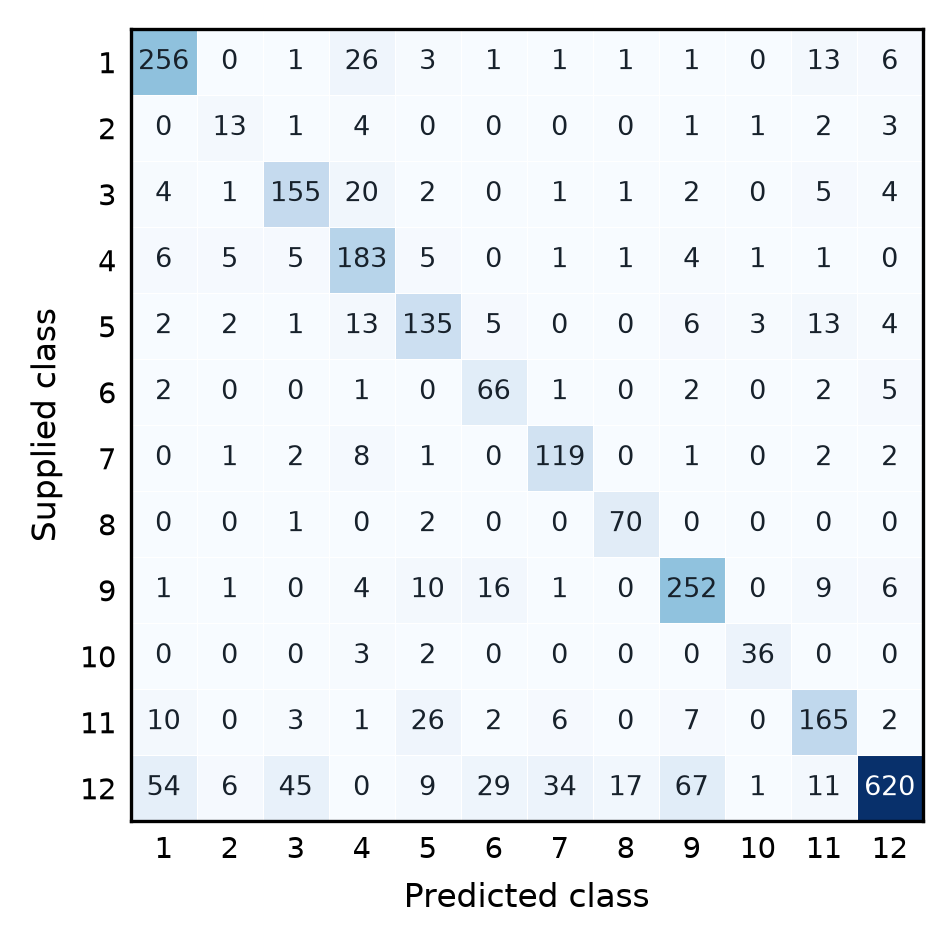

In [4]:
assets = build_paper_assets.main([])
display(Image(filename=str(ROOT / "paper_assets" / "confusion_matrix.png")))

## Ajustar em todo o treino e gerar o teste limpo

O ajuste usa todos os originais e o mesmo helper da configuração avaliada. O índice de exclusão é construído dos originais, nunca de descendentes sintéticos. O teste não determina grupos, modelos, parâmetros, fontes de augmentation ou a regra. A linha N de `results.txt` corresponde ao registo CSV N do teste, sem cabeçalho.

In [5]:
generate_results([])
inference = json.loads((ROOT / "outputs" / "final" / "inference.json").read_text(encoding="utf-8"))
assert inference["original_training_cases"] == 2669
assert inference["exclusion_index_original_training_rows"] == 2669
assert inference["test_cases"] == inference["results_lines"] == 398
assert inference["selected_model"]["candidate_id"] == selection["candidate_id"]
assert inference["test_metrics"] is None
print("Verified", inference["results_lines"], "ordered predictions; official test scores are unknown.")

Selected SVC+EXCL: LinearSVC / exclude_seen
Fit on all 2669 original cases; wrote 398 predictions to D:\projetos\faculdade\LN\help-the-doctors\results.txt.
Row/grouped scores are exploratory development CV. Official test scores are unknown.
Verified 398 ordered predictions; official test scores are unknown.
